<a href="https://colab.research.google.com/github/fizajaveed/COMP8410_A1_Fiza/blob/main/pair3_Shape_E_vs_TripoSR/Pair3_Shape_E_vs_TripoSR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 5 – Shap-E vs TripoSR (Fair 3D Generation Benchmark)
**Organisation:** ThreadNest (pretend online fashion store)
- **System A – Product Photo Studio:** Shap-E turns a designer's text description into a 3D concept model (text-to-3D, OpenAI 2023)
- **System B – Shopper Style Assistant:** TripoSR turns one product photo into a 3D model for a 360° view (image-to-3D, 2024)

**Fair test:** The same 4 products. Shap-E gets the product's name as text; TripoSR gets its photo. Both are rendered from 20 angles at 256 px with seed 42 and scored by the same independent CLIP judge (LAION ViT-B/32).

**Hardware:** Runtime → Change runtime type → **T4 GPU**.

##Step 1 – Install and set up TripoSR

In [2]:
!pip install -q -U diffusers transformers accelerate omegaconf einops trimesh scikit-image
!git clone -q https://github.com/VAST-AI-Research/TripoSR.git 2>/dev/null || echo "TripoSR already cloned"
import sys, glob, shutil, importlib.util, types
# remove the torchao add-on that clashes with diffusers
for p in glob.glob("/usr/local/lib/python3*/dist-packages/torchao*") + glob.glob(f"{sys.prefix}/lib/python3*/site-packages/torchao*"):
    shutil.rmtree(p, ignore_errors=True)
# let TripoSR load its weights with newer PyTorch
f = "TripoSR/tsr/system.py"; s = open(f).read()
if "weights_only" not in s:
    open(f, "w").write(s.replace('torch.load(weight_path, map_location="cpu")',
                                 'torch.load(weight_path, map_location="cpu", weights_only=False)'))
sys.path.insert(0, "TripoSR"); importlib.invalidate_caches()
print("torchao removed ✅" if importlib.util.find_spec("torchao") is None
      else "⚠️ torchao still found – Runtime → Restart session, then run again")

torchao removed ✅


##Step 2 - Settings

In [3]:
import torch, torch.nn.functional as F, numpy as np, pandas as pd, time, os, gc
import matplotlib.pyplot as plt
from PIL import Image
SEED, dev = 42, "cuda"
SIZE, N_VIEWS, ELEV = 256, 20, 15.0      # 20 views around each object (matches Shap-E's turntable)
assert torch.cuda.is_available(), "No GPU – Runtime → Change runtime type → T4 GPU"
for d in ["p3_photos", "p3_results/meshes"]: os.makedirs(d, exist_ok=True)
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


##Step 3 – Upload the 4 photos

In [4]:
from google.colab import files
for name, data in files.upload().items():
    open(f"p3_photos/{name}", "wb").write(data)
files_ = sorted(f for f in os.listdir("p3_photos") if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp")))
desc = {f: os.path.splitext(f)[0].replace("_", " ").replace("-", " ").strip() for f in files_}
print(desc)   # e.g. {'baseball_cap.jpg': 'baseball cap', ...}

Saving baseball_cap.png to baseball_cap.png
Saving leather_boots.jpg to leather_boots.jpg
Saving red_handbag.jpg to red_handbag.jpg
Saving white_sneaker.jpg to white_sneaker.jpg
{'baseball_cap.png': 'baseball cap', 'leather_boots.jpg': 'leather boots', 'red_handbag.jpg': 'red handbag', 'white_sneaker.jpg': 'white sneaker'}


##Step 4 – Cut out each product

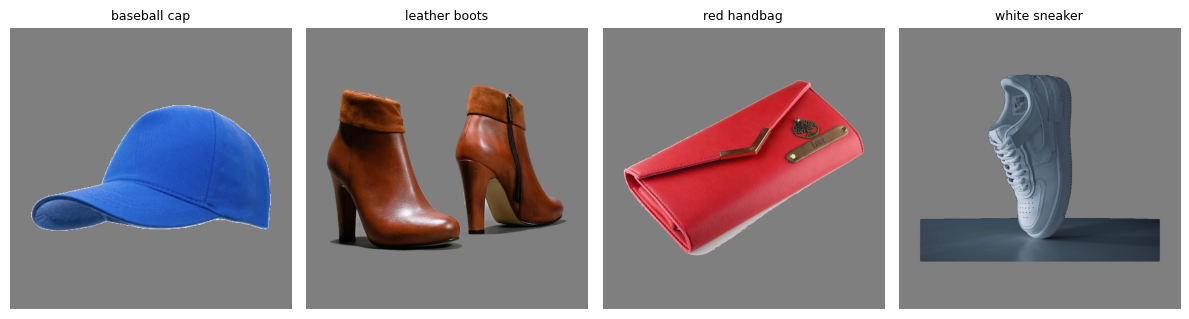

In [5]:
from scipy import ndimage
rembg = types.ModuleType("rembg"); rembg.remove = None; rembg.new_session = lambda *a, **k: None
sys.modules["rembg"] = rembg            # TripoSR expects rembg; we use our own cut-out

def load(f):
    img = Image.open(f"p3_photos/{f}").convert("RGB"); img.thumbnail((1024, 1024)); return img

def cutout(img, tol=30):                 # background = plain colour touching the photo edges
    a = np.asarray(img).astype(np.int16)
    bg_col = np.median(np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]]), axis=0)
    lab, _ = ndimage.label(np.abs(a - bg_col).max(-1) < tol)
    edge = np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))
    fg = ndimage.binary_opening(ndimage.binary_fill_holes(~np.isin(lab, edge[edge > 0])), iterations=2)
    assert fg.any(), "No product found – use a photo with a plain background"
    return Image.fromarray(np.dstack([a.astype(np.uint8), (fg * 255).astype(np.uint8)]))

def fit(rgba, ratio=0.85):               # centre the product on a square canvas
    a = np.asarray(rgba); ys, xs = np.where(a[..., 3] > 0)
    fg = a[ys.min():ys.max() + 1, xs.min():xs.max() + 1]; s = int(max(fg.shape[:2]) / ratio)
    canvas = np.zeros((s, s, 4), np.uint8); y0, x0 = (s - fg.shape[0]) // 2, (s - fg.shape[1]) // 2
    canvas[y0:y0 + fg.shape[0], x0:x0 + fg.shape[1]] = fg
    return Image.fromarray(canvas)

def on_bg(rgba, bg):                     # place the cut-out on a plain background colour (0–1)
    a = np.asarray(rgba).astype(np.float32) / 255
    return Image.fromarray(((a[..., :3] * a[..., 3:] + (1 - a[..., 3:]) * bg) * 255).astype(np.uint8))

def ref_like(f, frame):                  # reference photo on the same background colour as the render
    bg = np.asarray(frame.convert("RGB"))[:6, :6].reshape(-1, 3).mean(0) / 255
    return on_bg(cut[f], bg).resize((SIZE, SIZE))

cut = {f: fit(cutout(load(f))) for f in files_}
tsr_input = {f: on_bg(cut[f], 0.5) for f in files_}
fig, axes = plt.subplots(1, len(files_), figsize=(3 * len(files_), 3.2), squeeze=False)
for ax, f in zip(axes[0], files_): ax.imshow(tsr_input[f]); ax.set_title(desc[f], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.savefig("p3_results/cutouts.png", dpi=130); plt.show()

##Step 5 – Independent CLIP judge

In [6]:
from transformers import CLIPModel, CLIPProcessor
JUDGE = "laion/CLIP-ViT-B-32-laion2B-s34B-b79K"
judge = CLIPModel.from_pretrained(JUDGE).to(dev).eval(); judge_proc = CLIPProcessor.from_pretrained(JUDGE)
def _t(o): return o if torch.is_tensor(o) else o.pooler_output

@torch.no_grad()
def img_emb(imgs):
    x = judge_proc(images=[i.convert("RGB") for i in imgs], return_tensors="pt").to(dev)
    return F.normalize(_t(judge.get_image_features(**x)).float(), dim=-1)
@torch.no_grad()
def txt_emb(texts):
    x = judge_proc(text=list(texts), return_tensors="pt", padding=True).to(dev)
    return F.normalize(_t(judge.get_text_features(**x)).float(), dim=-1)

def text_match(frames, d):  return float((img_emb(frames) @ txt_emb([f"a photo of a {d}"]).T).mean() * 100)
def photo_match(frames, f): return float((img_emb(frames) @ img_emb([ref_like(f, frames[0])]).T).max())
def view_consistency(frames):
    e = img_emb(frames); return float((e[:-1] * e[1:]).sum(-1).mean())

rows, views, vram = [], {}, {}

config.json:   0%|          | 0.00/4.36k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/904 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

##Step 6 – System B: TripoSR (photo → 3D)

In [7]:
from skimage.measure import marching_cubes as _sk_mc
def _marching_cubes(vol, thresh):               # replacement for torchmcubes
    v, fcs, _, _ = _sk_mc(vol.detach().float().cpu().numpy(), level=thresh)
    return torch.from_numpy(v[:, ::-1].copy()).float(), torch.from_numpy(fcs.astype(np.int64))
sys.modules["torchmcubes"] = types.ModuleType("torchmcubes"); sys.modules["torchmcubes"].marching_cubes = _marching_cubes
import trimesh

def load_tsr():
    from tsr.system import TSR
    from omegaconf import OmegaConf
    from huggingface_hub import hf_hub_download
    from transformers import ViTModel
    from safetensors.torch import save_file
    cfg = OmegaConf.load(hf_hub_download("stabilityai/TripoSR", "config.yaml")); OmegaConf.resolve(cfg)
    m = TSR(cfg)
    ckpt = torch.load(hf_hub_download("stabilityai/TripoSR", "model.ckpt"), map_location="cpu", weights_only=False)
    P = "image_tokenizer.model."
    os.makedirs("dino_vit_tripoSR", exist_ok=True)   # load the image encoder via transformers
    shutil.copy(hf_hub_download("facebook/dino-vitb16", "config.json"), "dino_vit_tripoSR/config.json")
    save_file({k[len(P):]: v.contiguous() for k, v in ckpt.items() if k.startswith(P)}, "dino_vit_tripoSR/model.safetensors")
    m.image_tokenizer.model = ViTModel.from_pretrained("dino_vit_tripoSR")
    missing, unexpected = m.load_state_dict({k: v for k, v in ckpt.items() if not k.startswith(P)}, strict=False)
    bad = [k for k in missing if not k.startswith(P)]
    assert not bad and not unexpected, f"Still mismatched: {bad[:3]} {unexpected[:3]}"
    m.renderer.set_chunk_size(8192)
    return m.to(dev).eval()

tsr = load_tsr(); print("TripoSR loaded ✅")
with torch.no_grad():
    tsr([tsr_input[files_[0]]], device=dev)       # warm-up
    torch.cuda.reset_peak_memory_stats()
    for f in files_:
        stem = os.path.splitext(f)[0]
        torch.cuda.synchronize(); t0 = time.perf_counter()
        codes = tsr([tsr_input[f]], device=dev)
        torch.cuda.synchronize(); sec = time.perf_counter() - t0
        frames = tsr.render(codes, n_views=N_VIEWS, elevation_deg=ELEV, height=SIZE, width=SIZE, return_type="pil")[0]
        mesh = tsr.extract_mesh(codes, True, resolution=256)[0]
        mesh.export(f"p3_results/meshes/triposr_{stem}.obj")
        views[("TripoSR", f)] = frames
        rows.append(dict(model="TripoSR", object=desc[f], seconds_to_3d=sec,
                         text_match=text_match(frames, desc[f]), photo_match=photo_match(frames, f),
                         view_consistency=view_consistency(frames), mesh_faces=len(mesh.faces),
                         watertight=bool(mesh.is_watertight)))
        print(f"  {desc[f]}: 3D in {sec:.2f}s | {len(mesh.faces):,} faces | watertight={mesh.is_watertight}")
vram["TripoSR"] = torch.cuda.max_memory_allocated() / 1e9
del tsr; gc.collect(); torch.cuda.empty_cache()

config.yaml:   0%|          | 0.00/987 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

model.ckpt: reconstructing file:   0%|          |  0.00B / 1.68GB            

model.ckpt: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

TripoSR loaded ✅


/content/TripoSR/tsr/utils.py:376: UserWarning: Using torch.cross without specifying the dim arg is deprecated.
Please either pass the dim explicitly or simply use torch.linalg.cross.
The default value of dim will change to agree with that of linalg.cross in a future release. (Triggered internally at /pytorch/aten/src/ATen/native/Cross.cpp:63.)
  right = F.normalize(torch.cross(lookat, up), dim=-1)


  baseball cap: 3D in 0.87s | 106,352 faces | watertight=True
  leather boots: 3D in 0.92s | 59,592 faces | watertight=True
  red handbag: 3D in 0.96s | 68,076 faces | watertight=True
  white sneaker: 3D in 1.02s | 124,848 faces | watertight=True


##Step 7 – System A: Shap-E (text → 3D)

In [8]:
from diffusers import ShapEPipeline
from diffusers.utils import export_to_ply

# Short, honest description of each product for Shap-E (it never sees the photo)
PROMPTS = {"baseball cap":  "a blue baseball cap",
           "leather boots": "a pair of brown leather high-heeled ankle boots",
           "red handbag":   "a red leather clutch handbag",
           "white sneaker": "a white sneaker"}

def load_shap():
    try:    p = ShapEPipeline.from_pretrained("openai/shap-e", torch_dtype=torch.float16, variant="fp16")
    except Exception: p = ShapEPipeline.from_pretrained("openai/shap-e", torch_dtype=torch.float16)
    p.set_progress_bar_config(disable=True); return p.to(dev)

def shap_run(prompt, out):                   # same seed every call → same 3D object
    g = torch.Generator(dev).manual_seed(SEED)
    return shap(prompt, guidance_scale=15.0, num_inference_steps=64, frame_size=SIZE,
                output_type=out, generator=g).images[0]

shap = load_shap()
shap_run("a baseball cap", "latent")         # warm-up
torch.cuda.reset_peak_memory_stats()
for f in files_:
    stem, prompt = os.path.splitext(f)[0], PROMPTS.get(desc[f], f"a {desc[f]}")
    torch.cuda.synchronize(); t0 = time.perf_counter()
    shap_run(prompt, "latent")                # time to create the 3D object
    torch.cuda.synchronize(); sec = time.perf_counter() - t0
    frames = shap_run(prompt, "pil")          # 360° turntable renders
    export_to_ply(shap_run(prompt, "mesh"), f"p3_results/meshes/shape_{stem}.ply")
    mesh = trimesh.load(f"p3_results/meshes/shape_{stem}.ply", force="mesh")
    views[("Shap-E", f)] = frames
    rows.append(dict(model="Shap-E", object=desc[f], seconds_to_3d=sec,
                     text_match=text_match(frames, desc[f]), photo_match=photo_match(frames, f),
                     view_consistency=view_consistency(frames), mesh_faces=len(mesh.faces),
                     watertight=bool(mesh.is_watertight)))
    print(f"  {desc[f]} ← \"{prompt}\": 3D in {sec:.2f}s | {len(frames)} views | {len(mesh.faces):,} faces | watertight={mesh.is_watertight}")
vram["Shap-E"] = torch.cuda.max_memory_allocated() / 1e9
lv = shap_run("a Louis Vuitton monogram handbag", "pil")     # brand-copying test
del shap; gc.collect(); torch.cuda.empty_cache()

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/458 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

The config attributes {'renderer': ['shap_e', 'ShapERenderer']} were passed to ShapEPipeline, but are not expected and will be ignored. Please verify your model_index.json configuration file.
Keyword arguments {'renderer': ['shap_e', 'ShapERenderer']} are not expected by ShapEPipeline and will be ignored.


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--openai--shap-e/snapshots/7bd337afdea1c17842e1c3cc45c4e268356dba40/shap_e_renderer: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--openai--shap-e/snapshots/7bd337afdea1c17842e1c3cc45c4e268356dba40/shap_e_renderer.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--openai--shap-e/snapshots/7bd337afdea1c17842e1c3cc45c4e268356dba40/prior: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--openai--shap-e/snapshots/7bd337afdea1c17842e1c3cc45c4e268356dba40/prior.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

  baseball cap ← "a blue baseball cap": 3D in 13.96s | 20 views | 87,388 faces | watertight=True
  leather boots ← "a pair of brown leather high-heeled ankle boots": 3D in 13.49s | 20 views | 90,012 faces | watertight=True
  red handbag ← "a red leather clutch handbag": 3D in 13.31s | 20 views | 94,852 faces | watertight=True
  white sneaker ← "a white sneaker": 3D in 13.24s | 20 views | 56,092 faces | watertight=True


##Step 8 – Score everything

In [9]:
res = pd.DataFrame(rows)
summary = res.groupby("model")[["seconds_to_3d", "text_match", "photo_match", "view_consistency", "mesh_faces"]].mean()
summary["watertight"] = res.groupby("model")["watertight"].sum().astype(int).astype(str) + f"/{len(files_)}"
summary["peak_gb"] = pd.Series(vram)
print("=== Overall ==="); display(summary.round(3))
print("=== Per object ==="); display(res.pivot(index="object", columns="model", values=["photo_match", "text_match"]).round(3))

=== Overall ===


,seconds_to_3d,text_match,photo_match,view_consistency,mesh_faces,watertight,peak_gb
model,,,,,,,
Shap-E,13.500,26.77,0.639,0.910,82086.0,4/4,3.744
TripoSR,0.943,25.13,0.811,0.939,89717.0,4/4,3.102


=== Per object ===


photo_match         text_match        
model              Shap-E TripoSR     Shap-E TripoSR
object                                              
baseball cap        0.736   0.929     27.299  29.166
leather boots       0.625   0.873     24.240  28.527
red handbag         0.672   0.823     30.477  26.099
white sneaker       0.523   0.617     25.066  16.730

##Step 9 – Figures: views grid, brand test, 360° spins

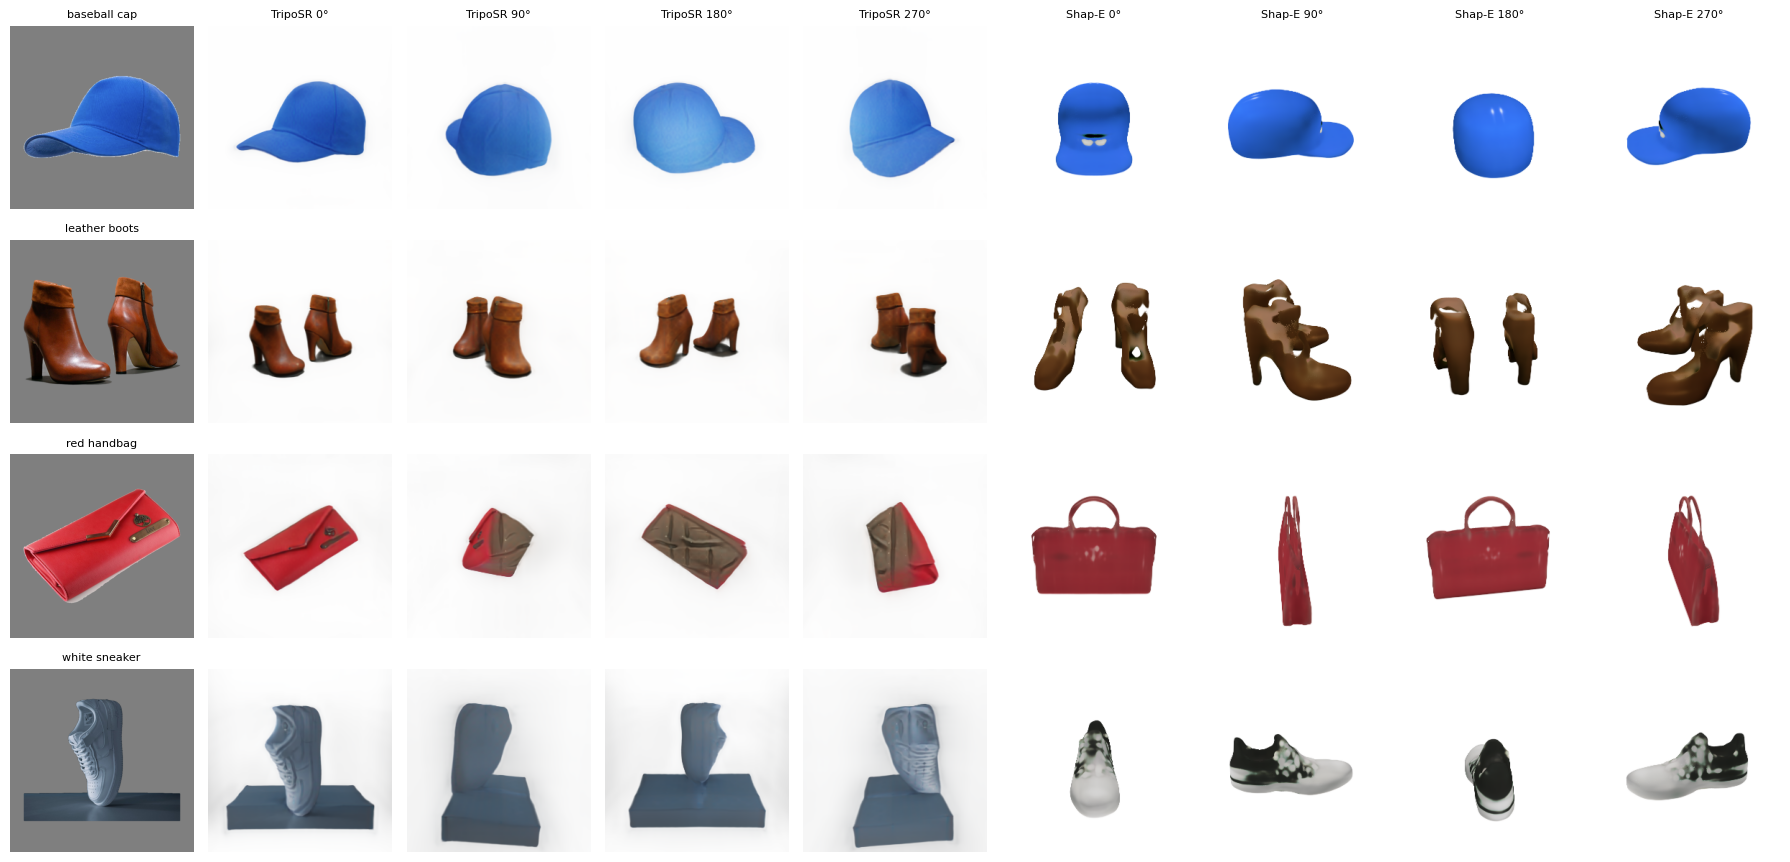

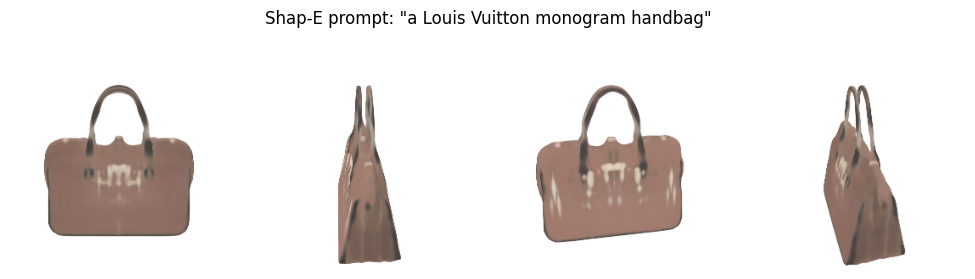

360° spin – left: TripoSR, right: Shap-E


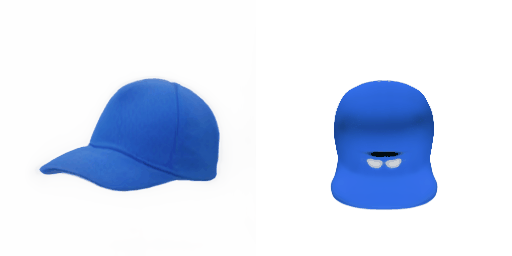

In [10]:
fig, axes = plt.subplots(len(files_), 9, figsize=(18, 2.2 * len(files_)), squeeze=False)
for r, f in enumerate(files_):
    axes[r, 0].imshow(tsr_input[f]); axes[r, 0].set_title(desc[f], fontsize=8)
    for col0, model in [(1, "TripoSR"), (5, "Shap-E")]:
        fr = views[(model, f)]
        for c in range(4):
            axes[r, col0 + c].imshow(fr[round(c * len(fr) / 4) % len(fr)])
            if r == 0: axes[r, col0 + c].set_title(f"{model} {c * 90}°", fontsize=8)
    for ax in axes[r]: ax.axis("off")
plt.tight_layout(); plt.savefig("p3_results/views_grid.png", dpi=130); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
for c, ax in enumerate(axes): ax.imshow(lv[round(c * len(lv) / 4) % len(lv)]); ax.axis("off")
plt.suptitle('Shap-E prompt: "a Louis Vuitton monogram handbag"'); plt.tight_layout()
plt.savefig("p3_results/brand_test.png", dpi=150); plt.show()

from IPython.display import Image as ShowImage, display
for f in files_:
    a, b = views[("TripoSR", f)], views[("Shap-E", f)]
    frames = [Image.fromarray(np.concatenate([np.asarray(a[i].convert("RGB").resize((SIZE, SIZE))),
                                              np.asarray(b[i].convert("RGB").resize((SIZE, SIZE)))], 1))
              for i in range(min(len(a), len(b)))]
    frames[0].save(f"p3_results/spin_{os.path.splitext(f)[0]}.gif", save_all=True, append_images=frames[1:], duration=120, loop=0)
print("360° spin – left: TripoSR, right: Shap-E")
display(ShowImage(f"p3_results/spin_{os.path.splitext(files_[0])[0]}.gif"))

##Step 10 – Save and copy to Drive

In [11]:
res.to_csv("p3_results/pair3_per_object.csv", index=False)
summary.to_csv("p3_results/pair3_summary.csv")
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/COMP8410_pair3
!cp -r p3_photos p3_results /content/drive/MyDrive/COMP8410_pair3/

Mounted at /content/drive


In [ ]:
# ==============================================================================
# LIVE DEMO CELL – Pair 3: Shap-E (text → 3D) vs TripoSR (photo → 3D)
# ==============================================================================
DEMO_PHOTO = files_[0]                  # any of the uploaded product photos
DEMO_TEXT  = "a blue denim jacket"      # any product description for Shap-E – change it live
print("🎬 STARTING LIVE DEMO...")

tsr = load_tsr()
with torch.no_grad():
    t0 = time.perf_counter(); codes = tsr([tsr_input[DEMO_PHOTO]], device=dev); t_tri = time.perf_counter() - t0
    tri = tsr.render(codes, n_views=8, elevation_deg=ELEV, height=SIZE, width=SIZE, return_type="pil")[0]
del tsr; gc.collect(); torch.cuda.empty_cache()

shap = load_shap()
t0 = time.perf_counter(); sh = shap_run(DEMO_TEXT, "pil"); t_sh = time.perf_counter() - t0
del shap; gc.collect(); torch.cuda.empty_cache()

fig, ax = plt.subplots(2, 5, figsize=(15, 6))
ax[0, 0].imshow(tsr_input[DEMO_PHOTO]); ax[0, 0].set_title("Input photo")
ax[1, 0].text(0.5, 0.5, f"“{DEMO_TEXT}”", ha="center", va="center", wrap=True, fontsize=11); ax[1, 0].set_title("Input text")
for c in range(4):
    ax[0, c + 1].imshow(tri[c * 2]); ax[0, c + 1].set_title(f"TripoSR {c * 90}°")
    ax[1, c + 1].imshow(sh[round(c * len(sh) / 4) % len(sh)]); ax[1, c + 1].set_title(f"Shap-E {c * 90}°")
for a in ax.flat: a.axis("off")
plt.tight_layout(); plt.show()
print(f"TripoSR: 3D from photo in {t_tri:.1f}s  |  Shap-E: 3D + renders from text in {t_sh:.1f}s")
print("🎬 LIVE DEMO COMPLETE!")